# Comparing conditions after FlowSOM clustering

After clustering, the usual next question is what differs between conditions. There are two kinds of differences:

1. Differential abundance (DA): does the share of a cell population change?
2. Differential state (DS): within a population, does the level of a functional marker, such as a phosphorylated signalling protein, change?

And there are two common study designs:

- Unpaired: each group consists of different people, for example patients and healthy controls.
- Paired: every person is measured in each condition, for example blood of each donor left unstimulated and stimulated.

This tutorial shows all four combinations with scverse tools: pytometry for clustering, scanpy for summaries per sample and [pertpy](https://pertpy.readthedocs.io) for the tests. We use simulated data, so that we know which differences are real and can check that the analysis finds them and nothing else.

## Background

**Test samples, not cells.** A sample contains thousands of cells, but they all come from one person, so they are not independent replicates. We therefore first summarise each sample and then test on these summaries. At the end of the first part we show what goes wrong otherwise.

**Abundance is compositional.** The number of cells per sample depends on how many cells were measured, so the counts only tell us the proportions of the populations, which add up to 1. The absolute number of cells of a population can grow without limit, but its proportion can only grow if the others shrink, so the proportions are negatively correlated. A t-test on the proportions of each population treats them as independent and can report populations that only shrank because another one grew. The negative binomial models of DESeq2 and edgeR, made for gene expression in RNA sequencing, also test each population on its own, and they normalise the samples by assuming that most features do not change, which holds for thousands of genes but is fragile for a handful of populations. Models made for compositional data, such as the Dirichlet-multinomial model of [scCODA](https://doi.org/10.1038/s41467-021-27150-6), describe all populations of a sample together. Here we use a simpler approach: we transform the counts to log-ratios with the centred log-ratio (CLR), which are unbounded and suit a linear model. The results remain relative to the other populations.

**State is not a count.** Unlike RNA sequencing, cytometry does not count molecules but measures a continuous intensity per cell, so count models do not apply. We summarise every population in every sample by the median of each state marker on the arcsinh scale, which is roughly normally distributed, and compare the medians with a linear model.

[pertpy](https://pertpy.readthedocs.io) offers many methods for both questions, among them scCODA and tascCODA for compositional data, Milo for differential abundance without clusters, and a range of tests and linear models for differential expression. We use its linear models, which handle both questions and both designs in the same way. They need pertpy's `de` extra, which is not a dependency of pytometry:

```
pip install "pertpy[de]"
```

In [1]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pertpy as pt
import scanpy as sc
import seaborn as sns
from scipy.stats import false_discovery_control

import pytometry as pm

## Simulate the data

The function below simulates a mass cytometry experiment on blood cells. There are six populations, defined by nine type markers, and three state markers. For every sample it draws the proportions of the populations and the levels of the state markers, with random differences between donors and between samples, and adds the effects we plant for the second condition. Then it draws 2,000 cells per sample around the mean profile of their population. Like an FCS file, it returns raw ion counts, with the sample, donor and condition of every cell in `obs`. It also keeps the true population of every cell in `obs["true_population"]`, so that we can check the clustering. With real data, you would instead read the FCS files and add the sample, donor and condition of every cell to `obs`.

In [2]:
# mean of every type marker in every population, on the arcsinh scale with cofactor 5
profiles = pd.DataFrame(
    {
        "CD4 T cells": {"CD45": 5, "CD3": 4, "CD4": 4},
        "CD8 T cells": {"CD45": 5, "CD3": 4, "CD8": 4},
        "B cells": {"CD45": 5, "CD19": 4, "HLA-DR": 4},
        "NK cells": {"CD45": 5, "CD8": 1.5, "CD56": 4},
        "monocytes": {"CD45": 4.5, "CD4": 1.5, "CD14": 4.5, "CD123": 1, "HLA-DR": 4},
        "pDCs": {"CD45": 4.5, "CD4": 1.5, "CD123": 4.5, "HLA-DR": 3.5},
    },
    index=["CD45", "CD3", "CD4", "CD8", "CD19", "CD14", "CD56", "CD123", "HLA-DR"],
).T.fillna(0)
proportions = pd.Series([0.35, 0.2, 0.12, 0.13, 0.15, 0.05], index=profiles.index)
type_markers = profiles.columns.tolist()
state_markers = ["pS6", "pERK", "pSTAT3"]


def simulate(conditions, paired, abundance_effects, state_effects, donor_sd=0.3, n_donors=6, seed=0):
    """Simulate raw ion counts of 2,000 cells per sample, with the given effects in the second condition.

    `abundance_effects` maps populations to fold changes of their proportion, `state_effects` maps
    (population, state marker) pairs to shifts on the arcsinh scale.
    """
    rng = np.random.default_rng(seed)
    n_populations, n_states = len(profiles), len(state_markers)
    donor_effects, X, obs = {}, [], []
    for i, condition in enumerate(conditions):
        for d in range(n_donors):
            donor = f"donor {d + 1}" if paired else f"{condition} {d + 1}"
            if donor not in donor_effects:  # every donor has their own proportions and state marker levels
                donor_effects[donor] = (
                    rng.normal(0, donor_sd, n_populations),
                    rng.normal(0, donor_sd, (n_populations, n_states)),
                )
            donor_logits, donor_states = donor_effects[donor]
            logits = np.log(proportions) + donor_logits + rng.normal(0, 0.1, n_populations)
            states = 1 + donor_states + rng.normal(0, 0.1, (n_populations, n_states))
            if i == 1:
                logits += np.log(pd.Series(abundance_effects, dtype=float).reindex(profiles.index, fill_value=1))
                for (population, marker), shift in state_effects.items():
                    states[profiles.index.get_loc(population), state_markers.index(marker)] += shift
            counts = rng.multinomial(2000, np.exp(logits) / np.exp(logits).sum())
            population = np.repeat(np.arange(n_populations), counts)
            means = np.hstack([profiles, states])[population]
            # back to ion counts: the inverse of the arcsinh transformation, with negative counts set to 0
            X.append(np.clip(5 * np.sinh(rng.normal(means, 0.6)), 0, None))
            obs.append(
                pd.DataFrame({"true_population": profiles.index[population], "donor": donor, "condition": condition})
            )
    obs = pd.concat(obs, ignore_index=True).rename(index=str)
    obs["sample_id"] = obs["donor"] + (", " + obs["condition"] if paired else "")
    obs = obs.astype("category")
    obs["condition"] = obs["condition"].cat.reorder_categories(list(conditions))
    var = pd.DataFrame(index=type_markers + state_markers)
    return ad.AnnData(np.vstack(X).astype(np.float32), obs=obs, var=var)

## Part 1: patients and healthy controls

The first study compares 6 patients with 6 healthy controls, so every sample comes from a different person. In the patients we plant two differences: monocytes are 2.5 times as abundant, and their pSTAT3 is higher by 1 on the arcsinh scale. Nothing else differs between the groups.

In [3]:
adata = simulate(
    conditions=["healthy", "patient"],
    paired=False,
    abundance_effects={"monocytes": 2.5},
    state_effects={("monocytes", "pSTAT3"): 1},
)
adata

AnnData object with n_obs × n_vars = 24000 × 12
    obs: 'true_population', 'donor', 'condition', 'sample_id'
    layers: None (.X)

### Transform and cluster

The values are raw ion counts, so we transform them with the inverse hyperbolic sine with cofactor 5, as is usual for mass cytometry.

Cell populations should be defined by the type markers only, so that a change in signalling does not split a population into several clusters. `markers=type_markers` restricts FlowSOM to the type markers, while all markers stay in `adata`. We ask for 6 clusters, as the simulated data contain 6 populations.

In [4]:
pm.tl.normalize_arcsinh(adata, cofactor=5)
pm.tl.flowsom_clustering(adata, key_added="cluster", markers=type_markers, min_clusters=6, max_clusters=6)

AnnData object with n_obs × n_vars = 24000 × 12
    obs: 'true_population', 'donor', 'condition', 'sample_id', 'cluster', 'cluster_som_node'
    uns: 'cluster'
    layers: None (.X)

To name the clusters, we look at the median of each type marker per cluster:

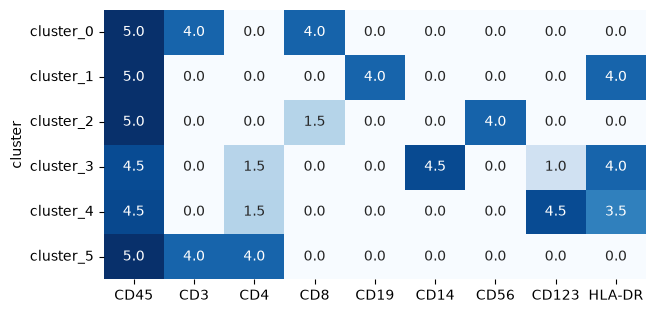

In [5]:
cluster_medians = sc.get.aggregate(adata[:, type_markers], by="cluster", func="median").to_df(layer="median")
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.heatmap(cluster_medians, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax)
ax.set(xlabel="", ylabel="cluster");

Rather than typing a name for every cluster number, we write down the marker profile of each population as a rule on these medians. The function checks that every cluster matches exactly one rule, so that a cluster that mixes two populations, or fits none, cannot go unnoticed.

In [6]:
rules = {
    "CD4 T cells": "CD3 > 2 and CD4 > 2",
    "CD8 T cells": "CD3 > 2 and CD8 > 2",
    "B cells": "CD19 > 2",
    "NK cells": "CD56 > 2",
    "monocytes": "CD14 > 2",
    "pDCs": "CD123 > 2",
}


def name_populations(adata):
    """Name the clusters by the rules, in `obs["population"]`."""
    medians = sc.get.aggregate(adata[:, type_markers], by="cluster", func="median").to_df(layer="median")
    matches = pd.DataFrame({name: medians.eval(rule) for name, rule in rules.items()})
    assert (matches.sum(axis=1) == 1).all(), "every cluster must match exactly one rule"
    names = adata.obs["cluster"].map(matches.idxmax(axis=1))
    adata.obs["population"] = pd.Categorical(names, categories=list(rules))


name_populations(adata)
adata.obs["population"].value_counts()

population
CD4 T cells    7389
CD8 T cells    5186
monocytes      5127
NK cells       2906
B cells        2276
pDCs           1116
Name: count, dtype: int64

Because the data are simulated, we can check the result against the true populations:

In [7]:
pd.crosstab(adata.obs["true_population"], adata.obs["population"])

population,CD4 T cells,CD8 T cells,B cells,NK cells,monocytes,pDCs
true_population,,,,,,
B cells,0,0,2276,0,0,0
CD4 T cells,7389,12,0,1,0,0
CD8 T cells,0,5174,0,0,0,0
NK cells,0,0,0,2905,0,0
monocytes,0,0,0,0,5127,0
pDCs,0,0,0,0,0,1116


Nearly every cell lands in its true population.

### Differential abundance

Now we reduce the cells to one row per sample: we count the cells of each population in each sample and divide by the number of cells of the sample to get proportions.

In [8]:
samples = adata.obs[["sample_id", "donor", "condition"]].drop_duplicates().set_index("sample_id")
sample_proportions = pd.crosstab(adata.obs["sample_id"], adata.obs["population"], normalize="index")
sample_proportions.round(3).head()

population,CD4 T cells,CD8 T cells,B cells,NK cells,monocytes,pDCs
sample_id,,,,,,
healthy 1,0.370,0.192,0.144,0.124,0.116,0.054
healthy 2,0.274,0.294,0.092,0.116,0.167,0.058
healthy 3,0.393,0.163,0.104,0.175,0.115,0.050
healthy 4,0.270,0.332,0.088,0.130,0.147,0.033
healthy 5,0.298,0.215,0.116,0.143,0.163,0.066


The proportions per sample, as violin plots with one dot per sample:

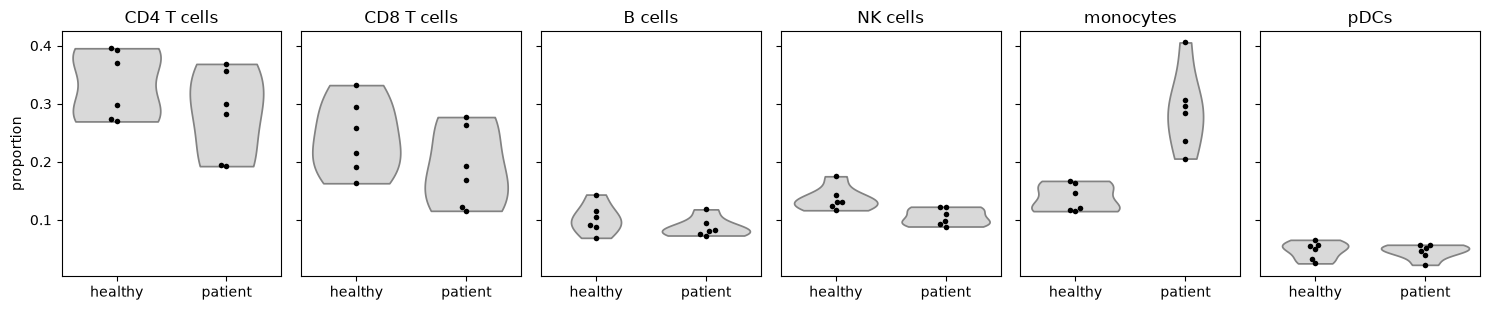

In [9]:
long_proportions = sample_proportions.stack().rename("proportion").reset_index().join(samples, on="sample_id")
fig, axes = plt.subplots(1, len(rules), figsize=(15, 3.2), sharey=True)
for ax, (population, values) in zip(axes, long_proportions.groupby("population", observed=True), strict=True):
    sns.violinplot(values, x="condition", y="proportion", inner=None, cut=0, color="0.85", ax=ax)
    sns.swarmplot(values, x="condition", y="proportion", color="black", size=4, ax=ax)
    ax.set(title=population, xlabel="")
fig.tight_layout()

Monocytes make up about twice as large a share of the cells in the patients. The plots also show the compositional effect described above: almost all other populations make up a slightly smaller share in the patients, although we did not change them, only because monocytes take up more of every sample.

We transform the cell counts of every sample with the CLR: the log2 of the count of each population minus the mean of these logs over all populations of the sample. A difference of 1 means that a population doubled relative to the geometric mean of all populations, which includes the population itself. We add 0.5 to the counts so that a population missing from a sample does not give the logarithm of 0. Then we fit a linear model of the CLR values on the condition, one per population, with pertpy's `Statsmodels`, which corrects the p-values over the populations with Benjamini-Hochberg.

In [10]:
def test_abundance(adata, baseline, group, paired_by=None):
    """Compare the CLR of the cell counts of every population between two conditions."""
    counts = pd.crosstab(adata.obs["sample_id"], adata.obs["population"])
    log_counts = np.log2(counts + 0.5)
    clr = log_counts.sub(log_counts.mean(axis=1), axis=0)
    samples = adata.obs[["sample_id", "donor", "condition"]].drop_duplicates().set_index("sample_id")
    data = ad.AnnData(clr.to_numpy(), obs=samples.loc[clr.index], var=pd.DataFrame(index=clr.columns.astype(str)))
    result = pt.tl.Statsmodels.compare_groups(
        data, column="condition", baseline=baseline, groups_to_compare=group, paired_by=paired_by
    )
    result = result.rename(columns={"variable": "population", "log_fc": "difference"})
    return result[["population", "difference", "p_value", "adj_p_value"]]


test_abundance(adata, "healthy", "patient").round(4)

,population,difference,p_value,adj_p_value
4,monocytes,1.0860,0.0001,0.0004
3,NK cells,-0.3328,0.0246,0.0737
1,CD8 T cells,-0.3493,0.2306,0.4303
2,B cells,-0.1663,0.2973,0.4303
0,CD4 T cells,-0.2269,0.3586,0.4303
5,pDCs,-0.0107,0.9658,0.9658


Only monocytes have an adjusted p-value below 0.05. Their difference is smaller than the planted log2(2.5) = 1.3, as the increase also raises the geometric mean. The other populations all have a small negative difference: the compositional shift seen in the plot. No method can tell from proportions alone which populations really changed in absolute numbers, so read the results as changes relative to the other populations. One large increase, together with a small decrease shared by all other populations, as here, points to a single population that grew.

### Differential state

For the state markers, we take the median of each marker over the cells of each population in each sample with `sc.get.aggregate`. This gives an AnnData with one observation per sample and population and the medians in the layer `"median"`. A median of very few cells is noisy, so we drop the medians of fewer than 50 cells.

In [11]:
pseudobulk = sc.get.aggregate(
    adata[:, state_markers], by=["sample_id", "donor", "condition", "population"], func="median"
)
pseudobulk = pseudobulk[pseudobulk.obs["n_obs_aggregated"] >= 50].copy()
pseudobulk

AnnData object with n_obs × n_vars = 71 × 3
    obs: 'sample_id', 'donor', 'condition', 'population', 'n_obs_aggregated'
    layers: 'median'

In every population, we fit the same linear model to the medians of every state marker. The difference between the group means is now on the arcsinh scale. pertpy corrects the p-values within every population only, so we correct the p-values over all populations and markers together.

In [12]:
def test_state(data, baseline, group, layer=None, paired_by=None):
    """Compare every marker in every population between two conditions, with FDR correction over all tests."""
    results = []
    for population in data.obs["population"].cat.categories:
        subset = data[data.obs["population"] == population]
        result = pt.tl.Statsmodels.compare_groups(
            subset, column="condition", baseline=baseline, groups_to_compare=group, layer=layer, paired_by=paired_by
        )
        results.append(result.assign(population=population))
    results = pd.concat(results, ignore_index=True).rename(columns={"variable": "marker", "log_fc": "difference"})
    results["adj_p_value"] = false_discovery_control(results["p_value"])
    return results[["population", "marker", "difference", "p_value", "adj_p_value"]]


state_results = test_state(pseudobulk, "healthy", "patient", layer="median")
state_results.sort_values("p_value").head().round(4)

,population,marker,difference,p_value,adj_p_value
12,monocytes,pSTAT3,0.8100,0.0007,0.0120
13,monocytes,pERK,-0.4464,0.0438,0.3564
3,CD8 T cells,pERK,0.4355,0.0657,0.3564
6,B cells,pERK,-0.3377,0.0978,0.3564
15,pDCs,pERK,0.2414,0.1022,0.3564


Of the 18 tests, only pSTAT3 in monocytes has an adjusted p-value below 0.05, with a difference of 0.8, close to the planted 1. The medians per sample:

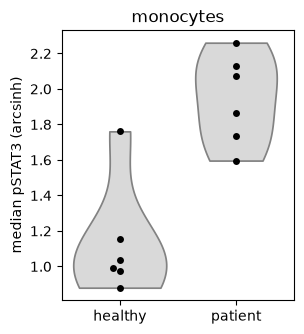

In [13]:
monocytes = pseudobulk[pseudobulk.obs["population"] == "monocytes"]
values = monocytes.obs.join(monocytes.to_df(layer="median"))
fig, ax = plt.subplots(figsize=(3, 3.5))
sns.violinplot(values, x="condition", y="pSTAT3", inner=None, cut=0, color="0.85", ax=ax)
sns.swarmplot(values, x="condition", y="pSTAT3", color="black", size=5, ax=ax)
ax.set(title="monocytes", xlabel="", ylabel="median pSTAT3 (arcsinh)");

### Why we test samples and not cells

What if we had skipped the summaries and compared the cells of patients with those of healthy controls directly? We run the same tests on the cells:

In [14]:
cell_results = test_state(adata[:, state_markers], "healthy", "patient")
print((cell_results["adj_p_value"] < 0.05).sum(), "of", len(cell_results), "tests with adjusted p < 0.05")

17 of 18 tests with adjusted p < 0.05


Nearly every test comes out significant, although we planted only one difference. Each person has their own level of every state marker, so two groups of six people always differ a little by chance. With thousands of cells per person, a test that counts every cell as a replicate is certain that these small chance differences are real. This is called pseudoreplication, and testing per-sample summaries avoids it.

## Part 2: unstimulated and stimulated cells of the same donors

The second study measures the cells of 6 donors twice, once unstimulated and once stimulated. We plant two differences in the stimulated cells: pS6 in B cells rises by 1.5, a strong effect, and pERK in CD4 T cells by 0.5, a weak one. The proportions of the populations do not change. Donors differ more from each other here (`donor_sd=0.5`), as basal signalling varies a lot between people.

In [15]:
adata = simulate(
    conditions=["unstim", "stim"],
    paired=True,
    abundance_effects={},
    state_effects={("B cells", "pS6"): 1.5, ("CD4 T cells", "pERK"): 0.5},
    donor_sd=0.5,
)
pm.tl.normalize_arcsinh(adata, cofactor=5)
pm.tl.flowsom_clustering(adata, key_added="cluster", markers=type_markers, min_clusters=6, max_clusters=6)
name_populations(adata)
pd.crosstab(adata.obs["true_population"], adata.obs["population"])

population,CD4 T cells,CD8 T cells,B cells,NK cells,monocytes,pDCs
true_population,,,,,,
B cells,0,0,2900,0,0,0
CD4 T cells,7913,0,0,0,0,0
CD8 T cells,2,5415,0,0,0,0
NK cells,0,0,0,3252,0,0
monocytes,0,0,0,0,3478,0
pDCs,0,0,0,0,0,1040


### Differential abundance

In a paired design, every donor has their own baseline, and we want to compare the conditions within each donor. `paired_by="donor"` adds the donor to the linear model, so that the model estimates a separate baseline for every donor:

In [16]:
test_abundance(adata, "unstim", "stim", paired_by="donor").round(4)

,population,difference,p_value,adj_p_value
0,CD4 T cells,0.0960,0.2874,0.93
3,NK cells,-0.1102,0.4669,0.93
2,B cells,0.0216,0.5961,0.93
1,CD8 T cells,-0.0243,0.8071,0.93
5,pDCs,0.0102,0.8906,0.93
4,monocytes,0.0069,0.9300,0.93


No population changes significantly, which is correct, since we did not change the proportions.

### Differential state

For the state markers, `paired_by="donor"` adds the donor to the linear model in the same way. For comparison, we also run the unpaired test, which ignores that the samples come in pairs:

In [17]:
pseudobulk = sc.get.aggregate(
    adata[:, state_markers], by=["sample_id", "donor", "condition", "population"], func="median"
)
pseudobulk = pseudobulk[pseudobulk.obs["n_obs_aggregated"] >= 50].copy()
paired = test_state(pseudobulk, "unstim", "stim", layer="median", paired_by="donor")
unpaired = test_state(pseudobulk, "unstim", "stim", layer="median")
comparison = paired.merge(
    unpaired.drop(columns="difference"), on=["population", "marker"], suffixes=("_paired", "_unpaired")
)
comparison.sort_values("p_value_paired").head().round(4)

,population,marker,difference,p_value_paired,adj_p_value_paired,p_value_unpaired,adj_p_value_unpaired
6,B cells,pS6,1.6205,0.0000,0.0002,0.0037,0.0671
0,CD4 T cells,pERK,0.4654,0.0001,0.0007,0.0358,0.3220
1,CD4 T cells,pS6,0.0510,0.0557,0.3345,0.8888,0.9798
3,CD8 T cells,pS6,0.0643,0.1451,0.6345,0.8655,0.9798
12,monocytes,pS6,0.1270,0.1765,0.6345,0.7163,0.9798


The paired test finds both planted effects and nothing else. The unpaired test misses both after correction, even the strong effect on pS6 in B cells. The paired test compares every donor with themselves, so the differences between donors no longer count as noise. The plot shows why this matters: the donors differ more from each other than the stimulation changes pERK, but within every donor, pERK goes up.

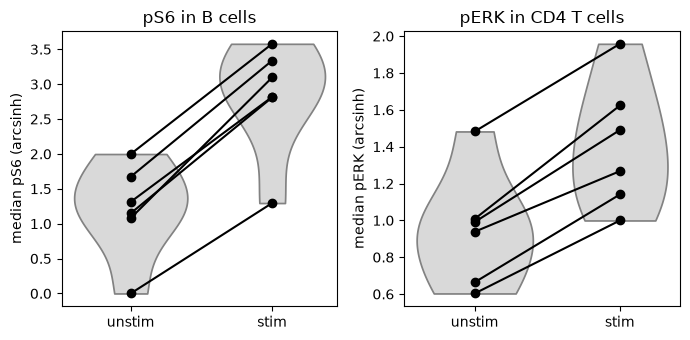

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
for ax, (population, marker) in zip(axes, [("B cells", "pS6"), ("CD4 T cells", "pERK")], strict=True):
    subset = pseudobulk[pseudobulk.obs["population"] == population]
    values = subset.obs.join(subset.to_df(layer="median"))
    sns.violinplot(values, x="condition", y=marker, inner=None, cut=0, color="0.85", ax=ax)
    # one line per donor, from unstimulated (x = 0) to stimulated (x = 1)
    ax.plot([0, 1], values.pivot(index="condition", columns="donor", values=marker), color="black", marker="o")
    ax.set(title=f"{marker} in {population}", xlabel="", ylabel=f"median {marker} (arcsinh)")
fig.tight_layout()

To adjust for further variables, such as the batch in which the samples were measured, fit `pt.tl.Statsmodels` with a formula such as `design="~condition + batch"` to the samples of each population, instead of calling `compare_groups`.

## Summary

Both questions and both designs follow the same recipe: summarise every sample, then fit a linear model per population with `pt.tl.Statsmodels.compare_groups`.

| Question | Summary per sample | Unpaired design | Paired design |
|---|---|---|---|
| Differential abundance | CLR of the cell counts of the populations | `compare_groups(...)` | `compare_groups(..., paired_by="donor")` |
| Differential state | median of every state marker in every population | `compare_groups(...)` | `compare_groups(..., paired_by="donor")` |

In both studies, this found the planted differences and nothing else, while a test on cells reported differences that are not there.

## Session info

In [19]:
import session_info2

session_info2.session_info()

Package,Version
pandas,3.1.0
anndata,0.13.4
matplotlib,3.11.2
numpy,2.5.4
pertpy,1.4.0
scanpy,1.12.4
seaborn,0.13.2
scipy,1.18.1
pytometry,0.2.0
Component,Info
